# GP1 — post-processing of the identified constitutive equations

Integrates eq. (7) with the coefficients of Tables 3–4 (`results/coefficients/`) and compares
it with the experiments. Panels are chosen by sample age, as labelled in the tables.

| Output | Paper |
|---|---|
| `figures/fig03_GP1_SAOS_lissajous.png` | Fig. 3 |
| `figures/fig05_GP1_LAOS_lissajous.png` | Fig. 5 |
| `figures/fig07_GP1_startup.png` | Fig. 7 |
| `figures/figS_GP1_coefficients.png` | coefficients vs. their physical analogues (Table 2) |

In [1]:
import matplotlib.pyplot as plt

from rhinn_sindy import figures
from rhinn_sindy.coefficients import load_laos_coefficients
from rhinn_sindy.plotting import save_figure, set_paper_style

MATERIAL = "GP1"
set_paper_style()
load_laos_coefficients(MATERIAL)

,sheet,age_h,time_min,c0,c1,c2,c3,c4,c5,c6,c7
0,16,1,6.13,0,0.1700,0.0420,0,0,0.000740,-0.000520,0
1,21,2,67.26,0,0.0900,0.0270,0,0,0.000760,0.000000,0
2,26,3,128.38,0,0.0650,0.0168,0,0,0.000800,0.000000,0
3,31,4,189.51,0,0.0460,0.0090,0,0,0.000600,0.000000,0
4,36,5,250.63,0,0.0340,0.0040,0,0,0.000500,0.000000,0
5,41,6,311.75,0,0.0170,0.0030,0,0,0.000300,0.000120,0
6,46,7,372.87,0,0.0200,0.0020,0,0,0.000200,0.000018,0
7,51,8,433.99,0,0.0020,0.0019,0,0,0.000054,0.000160,0
8,56,9,495.11,0,0.0036,0.0010,0,0,0.000000,0.000040,0


## Fig. 3 — SAOS Lissajous curves (0.05 % strain, 10 rad/s)

The measured loop is rebuilt from the stress amplitude and phase angle of the time sweep;
the model loop is the steady cycle of $\dot\gamma = c_1\sigma + c_2\dot\sigma$.

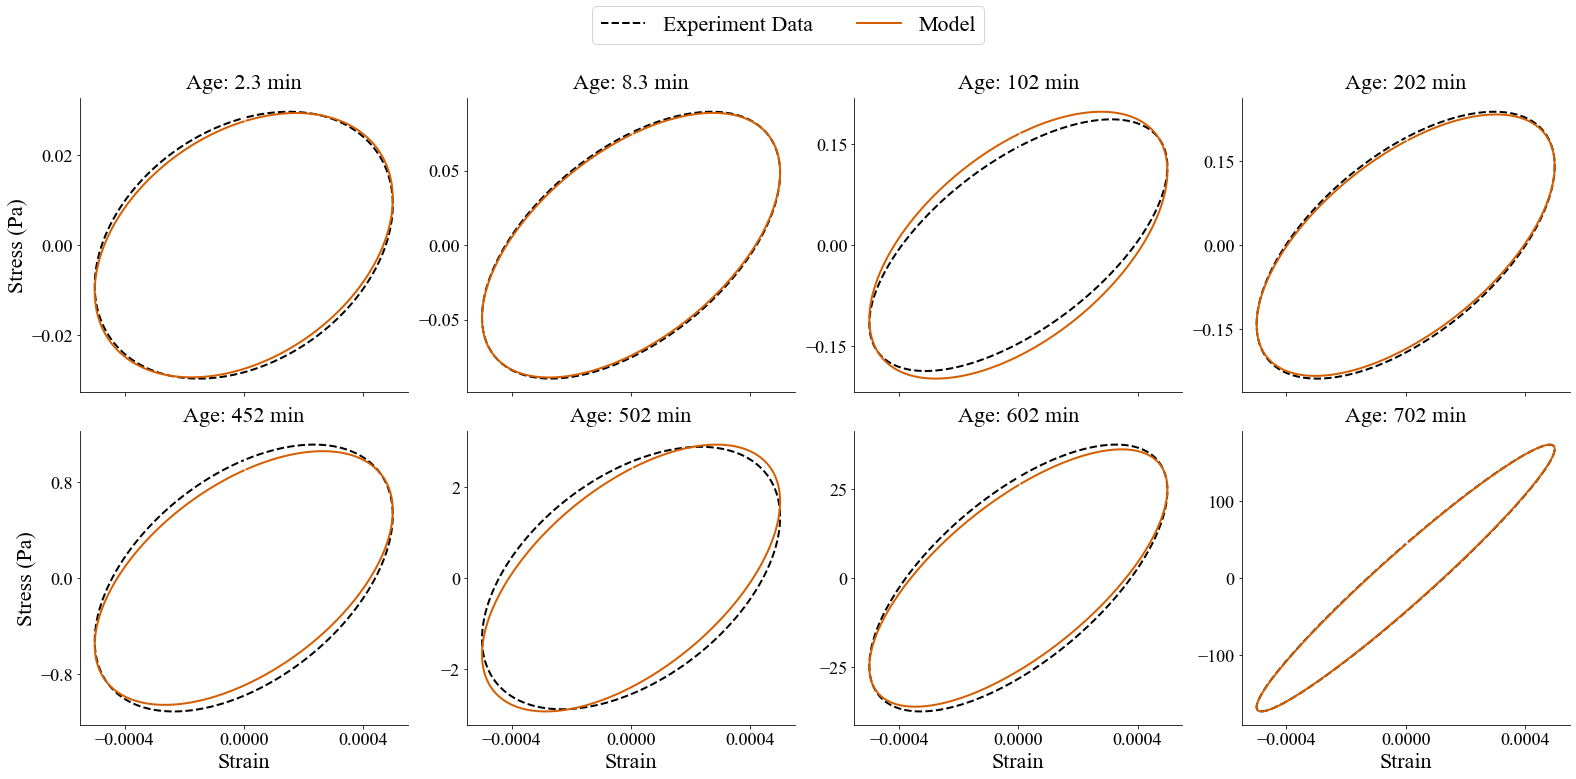

In [2]:
# Ages in minutes (Table 3).
fig = figures.saos_lissajous(MATERIAL, ages=[2, 8, 102, 202, 452, 502, 602, 702], nrows=2, ncols=4)
save_figure(fig, "fig03_GP1_SAOS_lissajous.png", pad_inches=0.15)
plt.show()

## Fig. 5 — LAOS Lissajous curves (10 Pa, 1 rad/s)

The fitted imposed stress drives eq. (7), integrated from the first measured strain.

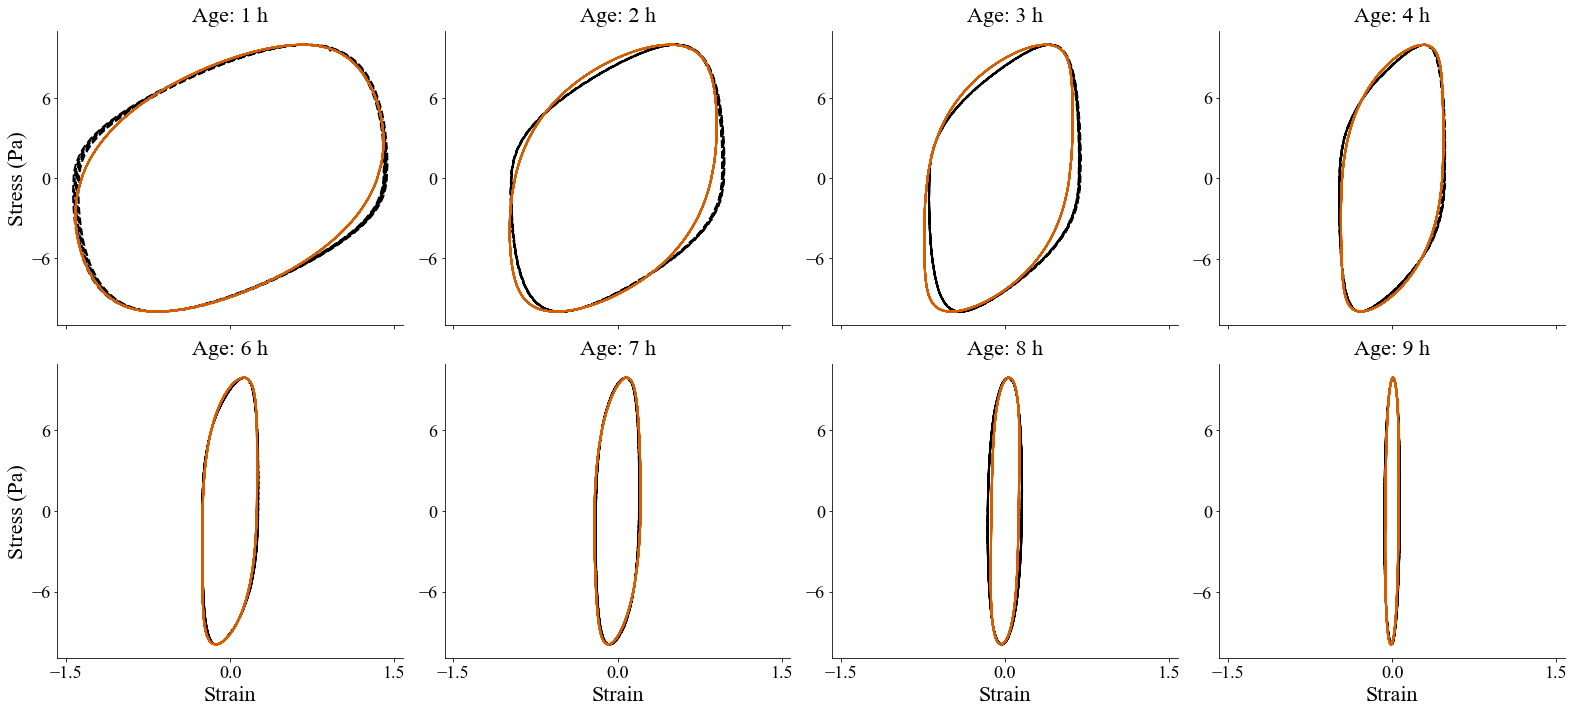

In [3]:
# Ages in hours (Table 4).
fig = figures.laos_lissajous(MATERIAL, ages=[1, 2, 3, 4, 6, 7, 8, 9], nrows=2, ncols=4)
save_figure(fig, "fig05_GP1_LAOS_lissajous.png", pad_inches=0.15)
plt.show()

## Fig. 7 — start-up shear at 3, 6 and 9 h

A protocol not used in training: constant shear rate from rest. It checks that the
identified equations stay bounded.

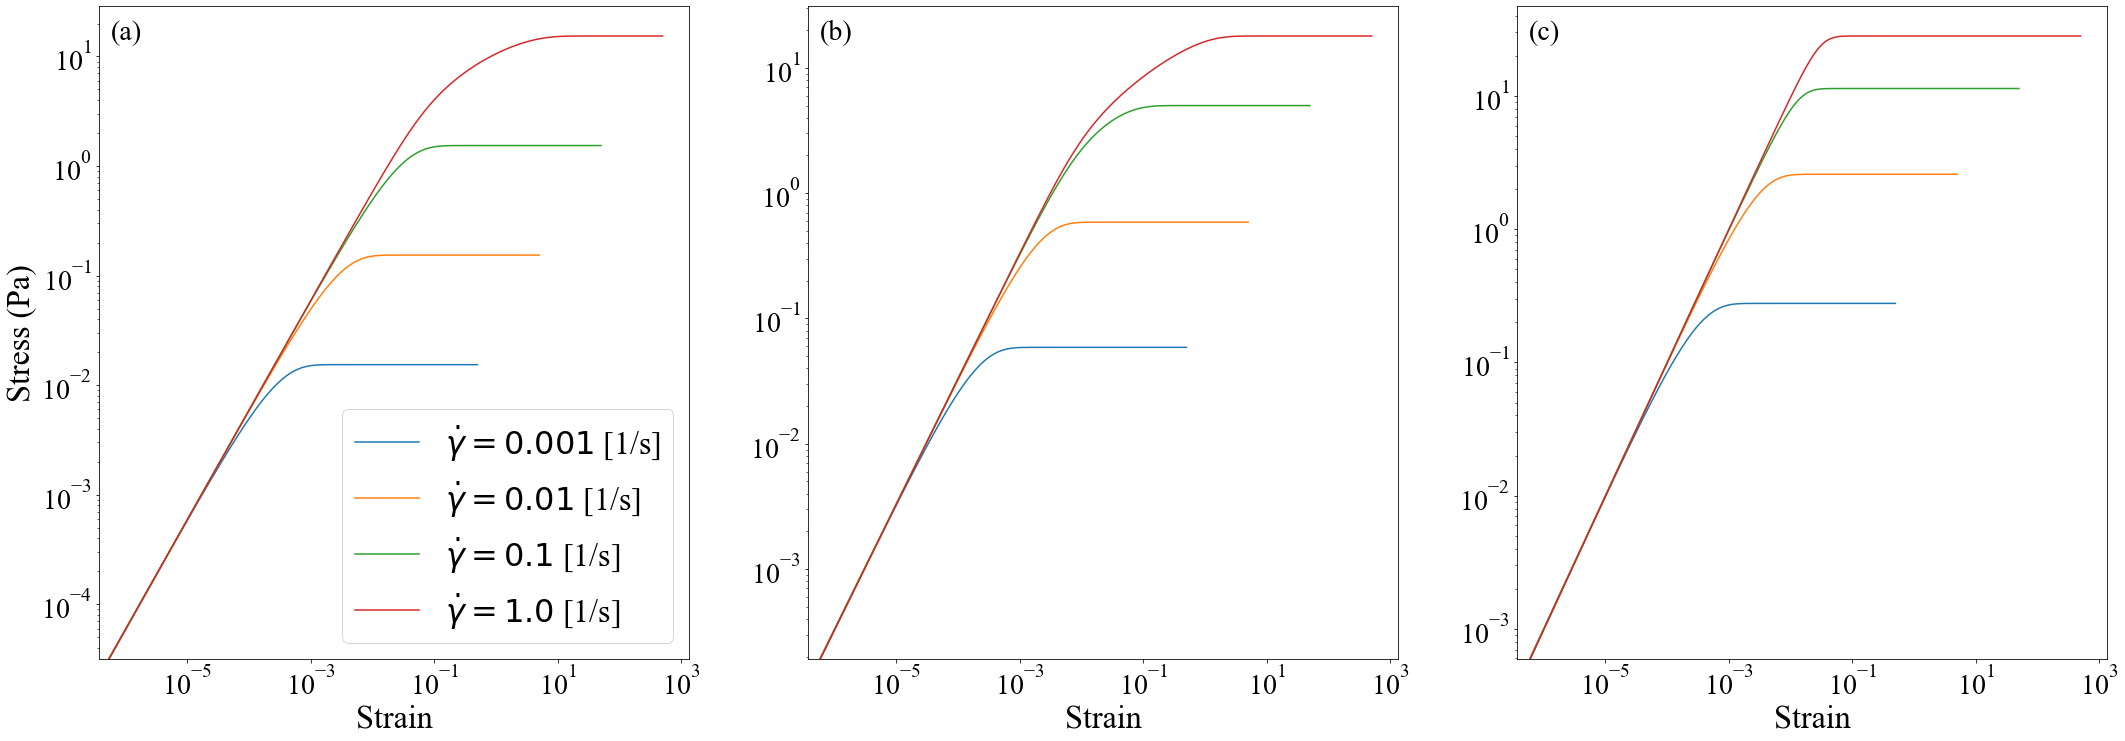

In [4]:
fig = figures.startup(MATERIAL, ages=[3, 6, 9], ylabel_all=False)
save_figure(fig, "fig07_GP1_startup.png")
plt.show()

## Coefficients vs. their physical analogues (Table 2)

Each coefficient is plotted with the combination of η and G′ it represents.

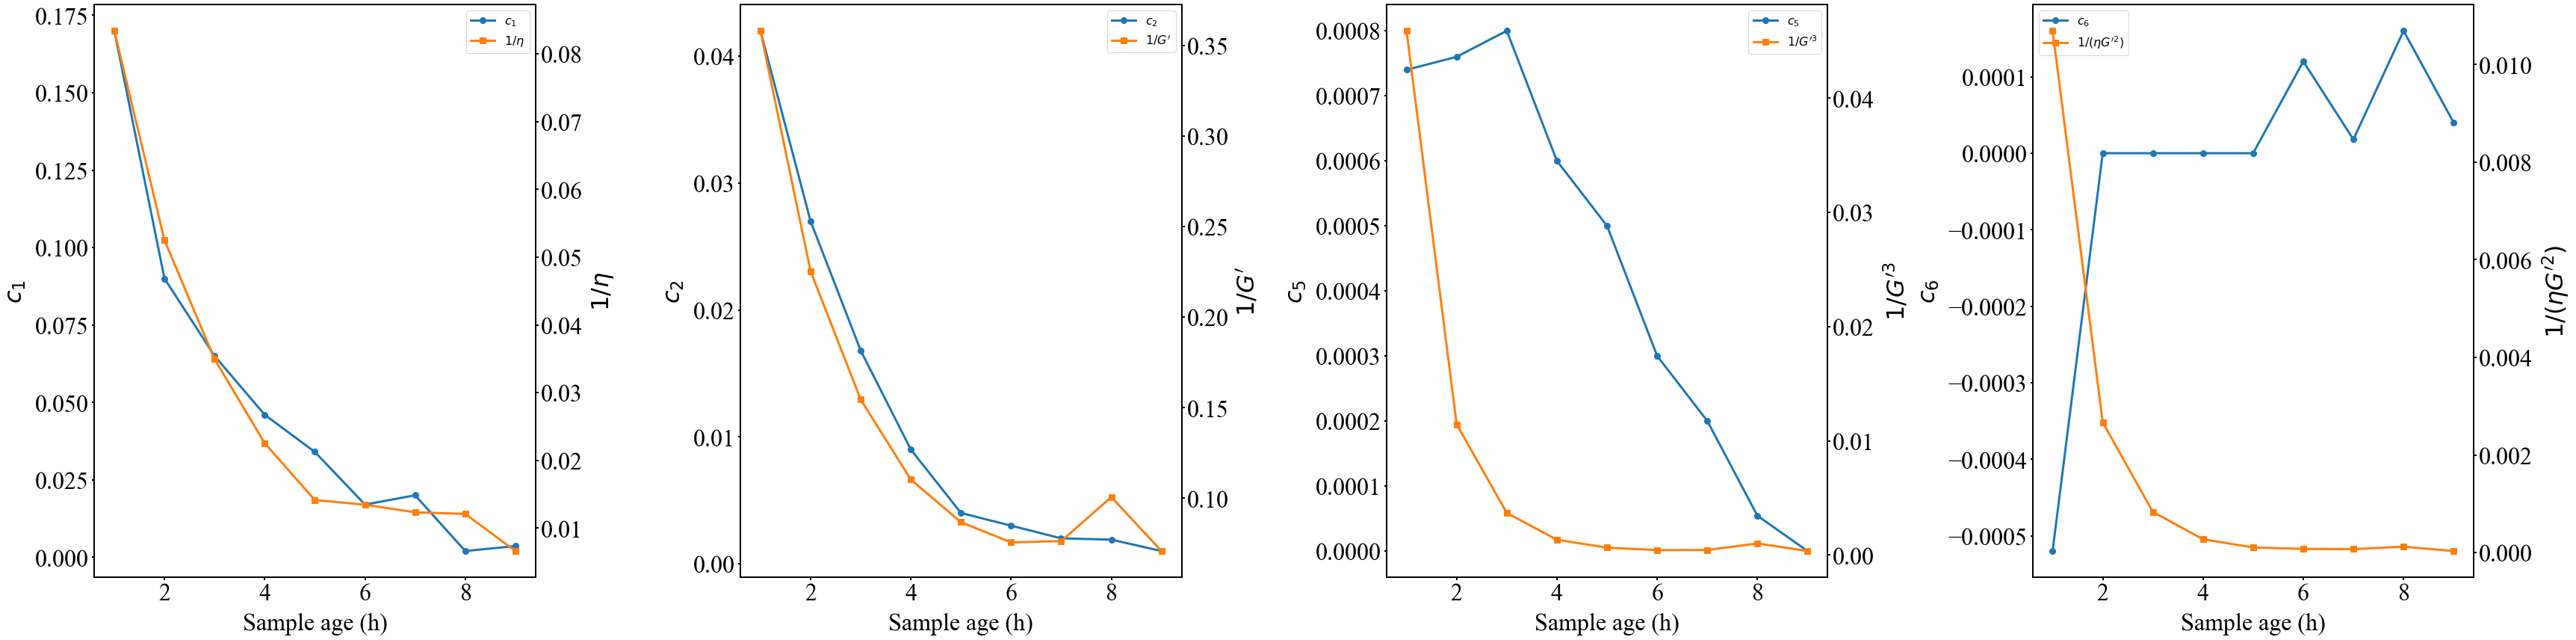

In [5]:
fig = figures.coefficient_analogues(MATERIAL)
save_figure(fig, "figS_GP1_coefficients.png")
plt.show()